# Método CASTLE · Notebook 2: Simulación, Tamaño y Libre de sesgos
**Castle Quant** — De la predicción del modelo a una estrategia: entrada y salida, tamaño de la operación, apalancamiento y pruebas de sesgos.

In [1]:
# signal = model(x)
# orders = strategy(signal)
# execute(orders)

In [2]:
# En el Notebook 1 (C · Captura y A · Alfa) construimos un modelo que predice el retorno logarítmico futuro.

In [3]:
# En este notebook usamos sus predicciones para construir una estrategia y comprobar si la ventaja es real:
# S · Simulación      -> ¿sobrevive a las comisiones?
# T · Tamaño          -> ¿cuánto operar y con cuánto apalancamiento?
# L · Libre de sesgos -> ¿la ventaja es real o es un espejismo?

In [4]:
# El modelo usa los rezagos 1 y 3 de las velas de 12 horas. Más adelante lo vemos en detalle.

### Tipos de Estrategia

In [5]:
# 1 Estrategias maker => proveen liquidez => agregan liquidez al mercado y buscan ser compensadas por ello
# 2 Estrategias taker => consumen liquidez => órdenes a mercado que consumen liquidez => en estas nos vamos a enfocar

In [6]:
# Preguntas clave para nuestra estrategia taker

# 1. Entrada / Salida
# 2. Tamaño de la operación
# 3. Apalancamiento
# 4. ¿Podemos creerle al resultado?

In [7]:
## el objetivo clave es crear una estrategia que maximice las ganancias a partir de la ventaja estadística del modelo

### Importar Librerías

In [8]:
# Solo en Google Colab: trae las librerías del método, el modelo entrenado y las velas de 12 horas
import os, sys
if 'google.colab' in sys.modules and not os.path.exists('research.py'):
    !git clone --depth 1 https://github.com/JuliRey2000/metodo_CASTLE_castlequant.com.git
    %cd metodo_CASTLE_castlequant.com

In [9]:
# Librerías de datos y análisis
import polars as pl                         # DataFrames rápidos para datos financieros
import numpy as np                          # Librería de cálculo numérico

# Librerías de machine learning
import torch                                # Framework PyTorch
import research                             # Utilidades para construir, simular y probar estrategias
import models                               # El modelo lineal del Notebook 1

# Fuentes de datos
import binance                              # Comisiones de Binance Futures

pl.Config.set_tbl_cols(-1);                 # Mostrar todas las columnas sin truncar

### Cargar el Modelo

In [10]:
# El modelo predice a 12 horas: con horizontes más cortos las comisiones se comían toda la ganancia.
# Usa 2 variables: el retorno de la última vela (lag_1) y el de hace tres velas (lag_3).

In [11]:
model = models.LinearModel(2)
# alerta de seguridad: se cargan solo los pesos (weights_only=True)
model.load_state_dict(torch.load('model_weights.pth', weights_only=True))
model.eval()

LinearModel(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)

### Parámetros del Modelo

In [12]:
research.print_model_params(model)

linear.weight:
[[-0.00699938  0.01524278]]
linear.bias:
[0.0002775]


### ¿Qué es la Reversión a la Media?

In [13]:
series = [-0.014000, 0.011399, -0.012212, 0.01997, -0.01442, 0.01227]
mu = np.mean(series)
mean_reversion_df = pl.DataFrame({'log_return': series, 'mean': mu})
mean_reversion_df

log_return,mean
f64,f64
-0.014,0.000501
0.011399,0.000501
-0.012212,0.000501
0.01997,0.000501
-0.01442,0.000501
0.01227,0.000501


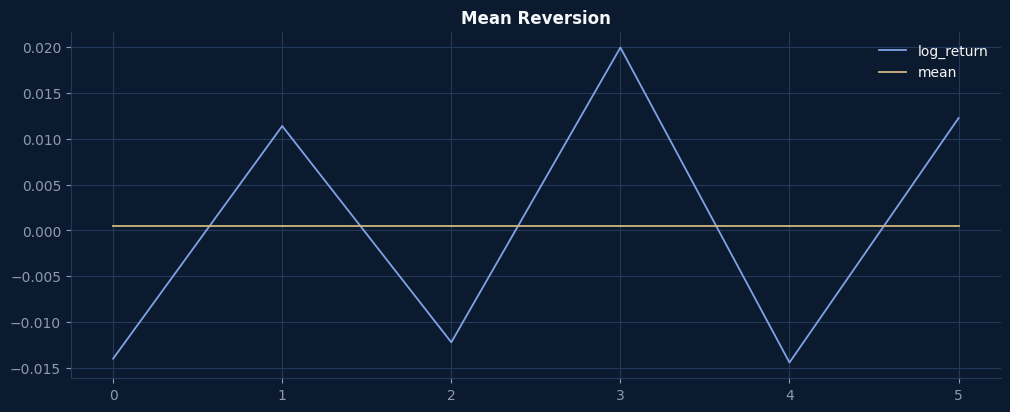

In [14]:
research.plot_multiple_lines(mean_reversion_df, ['log_return','mean'], 'Mean Reversion')

### Interpretabilidad - Modelo Lineal

In [15]:
def linear_model(x1, x3):
    w1, w3, b = -0.0070, 0.0152, 0.00028
    return w1 * x1 + w3 * x3 + b

# la última vela subió 5%: el peso negativo de lag_1 predice una devolución (reversión a la media)
linear_model(0.05, 0.0)

-7.000000000000008e-05

In [16]:
# hace tres velas el precio cayó 3%: el peso positivo de lag_3 predice que la caída continúa (momentum)
linear_model(0.0, -0.03)

-0.000176

In [17]:
# sin movimiento reciente solo queda el sesgo, que es positivo: el modelo aprendió de un mercado alcista
linear_model(0.0, 0.0)

0.00028

### Interpretabilidad - Modelo No Lineal

In [18]:
def nn_model(x):
    x = torch.tensor([x])
    W = torch.tensor([0.08035, -0.01478, -0.03523,  0.06777,  0.03789,  0.0013991, -0.13303,  0.8045])
    b = torch.tensor([0.16421])
    return torch.tanh(torch.sum(x * W) + b)

nn_model(-0.015)

tensor([0.1509])

In [19]:
# no es interpretable
nn_model(0.02)

tensor([0.1785])

In [20]:
# no se trata de desmerecer a las redes neuronales
# pero en trading las redes neuronales pueden aumentar el valor esperado a costa de más complejidad
# los modelos lineales suelen ser preferibles porque son interpretables, poco sensibles al ruido y menos propensos al sobreajuste (generalizan mejor)

## ¡Desarrollo de la Estrategia!

### Cargar la Serie de Tiempo

In [21]:
sym = 'BTCUSDT'
time_interval = '12h'

ts = pl.read_csv(f"{sym}_{time_interval}_ohlc.csv", try_parse_dates=True).sort('datetime')
ts

datetime,open,high,low,close
datetime[μs],f64,f64,f64,f64
2022-01-01 00:00:00,46210.57,47566.66,46210.55,46755.01
2022-01-01 12:00:00,46755.01,47943.77,46755.01,47704.35
2022-01-02 00:00:00,47704.35,47745.61,46749.99,47231.3
2022-01-02 12:00:00,47231.29,48000.0,46605.68,47280.0
2022-01-03 00:00:00,47280.01,47436.26,46717.26,47364.11
…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6


### Agregar el Objetivo y las Variables

In [22]:
forecast_horizon = 1
ts = research.add_log_return_features(ts, 'close', forecast_horizon, max_no_lags=4).drop_nulls()
ts

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2022-01-03 12:00:00,47364.11,47575.22,45665.4,46445.81,-0.019579,0.001777,0.001031,-0.009966,0.020101
2022-01-04 00:00:00,46445.8,46750.0,45931.61,46709.98,0.005672,-0.019579,0.001777,0.001031,-0.009966
2022-01-04 12:00:00,46709.97,47524.36,45445.57,45833.42,-0.018944,0.005672,-0.019579,0.001777,0.001031
2022-01-05 00:00:00,45833.41,47075.29,45710.23,46271.93,0.009522,-0.018944,0.005672,-0.019579,0.001777
2022-01-05 12:00:00,46271.93,46820.83,42270.0,43421.69,-0.063576,0.009522,-0.018944,0.005672,-0.019579
…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132


### División Temporal

In [23]:
# la misma partición del Notebook 1: 60% entrenamiento, 20% validación, 20% prueba
# trades = el tramo de prueba. El modelo nunca lo ha visto y aquí lo abrimos por primera y única vez
val_size, test_size = 0.2, 0.2
_, val_trades, trades = research.timeseries_split(ts, val_size, test_size)
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,103456.0,97959.0,99654.3,-0.03205,0.012657,-0.032668,0.018984,-0.021612
2025-11-14 00:00:00,99654.3,99862.8,95597.9,96134.6,-0.035958,-0.03205,0.012657,-0.032668,0.018984
2025-11-14 12:00:00,96134.5,97377.6,93955.0,94544.9,-0.016674,-0.035958,-0.03205,0.012657,-0.032668
2025-11-15 00:00:00,94544.9,96800.0,94523.9,95657.3,0.011697,-0.016674,-0.035958,-0.03205,0.012657
2025-11-15 12:00:00,95657.3,96439.6,95072.1,95560.3,-0.001015,0.011697,-0.016674,-0.035958,-0.03205
…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132


---
# S · Simulación
## Decisión de Estrategia #1: Señal de Entrada / Salida

In [24]:
# p1: ¿cuándo entramos? señal de entrada
# p2: ¿cuándo salimos? señal de salida

In [25]:
# 1. Basada en tiempo
# 2. Basada en una condición

In [26]:
# ejemplo de condición => solo operamos si y_hat está por encima o por debajo de cierto umbral

In [27]:
# basada en tiempo => cada 12 horas, al cerrar la vela, el modelo decide la dirección de la vela siguiente.
# si la dirección cambia, se cierra la posición y se abre la contraria (2 operaciones); si no cambia, se mantiene (0 operaciones)

### Agregar las Predicciones del Modelo

In [28]:
target = 'close_log_return'
features = [f'{target}_lag_1', f'{target}_lag_3']
trades = research.add_model_predictions(trades, model, features)
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,103456.0,97959.0,99654.3,-0.03205,0.012657,-0.032668,0.018984,-0.021612,0.000478
2025-11-14 00:00:00,99654.3,99862.8,95597.9,96134.6,-0.035958,-0.03205,0.012657,-0.032668,0.018984,0.000004
2025-11-14 12:00:00,96134.5,97377.6,93955.0,94544.9,-0.016674,-0.035958,-0.03205,0.012657,-0.032668,0.000722
2025-11-15 00:00:00,94544.9,96800.0,94523.9,95657.3,0.011697,-0.016674,-0.035958,-0.03205,0.012657,-0.000094
2025-11-15 12:00:00,95657.3,96439.6,95072.1,95560.3,-0.001015,0.011697,-0.016674,-0.035958,-0.03205,-0.000352
…,…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296,0.00046
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298,0.000472
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132,0.000111


### Agregar la Señal Direccional

In [29]:
trades = trades.with_columns(pl.col('y_hat').sign().alias('dir_signal'))
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat,dir_signal
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,103456.0,97959.0,99654.3,-0.03205,0.012657,-0.032668,0.018984,-0.021612,0.000478,1.0
2025-11-14 00:00:00,99654.3,99862.8,95597.9,96134.6,-0.035958,-0.03205,0.012657,-0.032668,0.018984,0.000004,1.0
2025-11-14 12:00:00,96134.5,97377.6,93955.0,94544.9,-0.016674,-0.035958,-0.03205,0.012657,-0.032668,0.000722,1.0
2025-11-15 00:00:00,94544.9,96800.0,94523.9,95657.3,0.011697,-0.016674,-0.035958,-0.03205,0.012657,-0.000094,-1.0
2025-11-15 12:00:00,95657.3,96439.6,95072.1,95560.3,-0.001015,0.011697,-0.016674,-0.035958,-0.03205,-0.000352,-1.0
…,…,…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296,0.00046,1.0
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298,0.000472,1.0
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132,0.000111,1.0


### Calcular el Retorno Logarítmico de la Operación

In [30]:
trades = trades.with_columns((pl.col('close_log_return')*pl.col('dir_signal')).alias('trade_log_return'))
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat,dir_signal,trade_log_return
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,103456.0,97959.0,99654.3,-0.03205,0.012657,-0.032668,0.018984,-0.021612,0.000478,1.0,-0.03205
2025-11-14 00:00:00,99654.3,99862.8,95597.9,96134.6,-0.035958,-0.03205,0.012657,-0.032668,0.018984,0.000004,1.0,-0.035958
2025-11-14 12:00:00,96134.5,97377.6,93955.0,94544.9,-0.016674,-0.035958,-0.03205,0.012657,-0.032668,0.000722,1.0,-0.016674
2025-11-15 00:00:00,94544.9,96800.0,94523.9,95657.3,0.011697,-0.016674,-0.035958,-0.03205,0.012657,-0.000094,-1.0,-0.011697
2025-11-15 12:00:00,95657.3,96439.6,95072.1,95560.3,-0.001015,0.011697,-0.016674,-0.035958,-0.03205,-0.000352,-1.0,0.001015
…,…,…,…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296,0.00046,1.0,-0.027432
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298,0.000472,1.0,-0.007942
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132,0.000111,1.0,-0.000431


### Calcular el Retorno Logarítmico Acumulado

In [31]:
trades = trades.with_columns(pl.col('trade_log_return').cum_sum().alias('cum_trade_log_return'))
trades

datetime,open,high,low,close,close_log_return,close_log_return_lag_1,close_log_return_lag_2,close_log_return_lag_3,close_log_return_lag_4,y_hat,dir_signal,trade_log_return,cum_trade_log_return
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,103456.0,97959.0,99654.3,-0.03205,0.012657,-0.032668,0.018984,-0.021612,0.000478,1.0,-0.03205,-0.03205
2025-11-14 00:00:00,99654.3,99862.8,95597.9,96134.6,-0.035958,-0.03205,0.012657,-0.032668,0.018984,0.000004,1.0,-0.035958,-0.068008
2025-11-14 12:00:00,96134.5,97377.6,93955.0,94544.9,-0.016674,-0.035958,-0.03205,0.012657,-0.032668,0.000722,1.0,-0.016674,-0.084683
2025-11-15 00:00:00,94544.9,96800.0,94523.9,95657.3,0.011697,-0.016674,-0.035958,-0.03205,0.012657,-0.000094,-1.0,-0.011697,-0.09638
2025-11-15 12:00:00,95657.3,96439.6,95072.1,95560.3,-0.001015,0.011697,-0.016674,-0.035958,-0.03205,-0.000352,-1.0,0.001015,-0.095365
…,…,…,…,…,…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,81953.7,77868.4,77962.6,-0.027432,-0.014593,0.000132,0.005298,0.012296,0.00046,1.0,-0.027432,-0.547269
2026-10-30 00:00:00,77962.6,78776.5,76444.0,77345.9,-0.007942,-0.027432,-0.014593,0.000132,0.005298,0.000472,1.0,-0.007942,-0.555211
2026-10-30 12:00:00,77345.8,78081.3,76270.0,77312.6,-0.000431,-0.007942,-0.027432,-0.014593,0.000132,0.000111,1.0,-0.000431,-0.555641


### Mostrar la Curva de Capital (Escala Logarítmica)

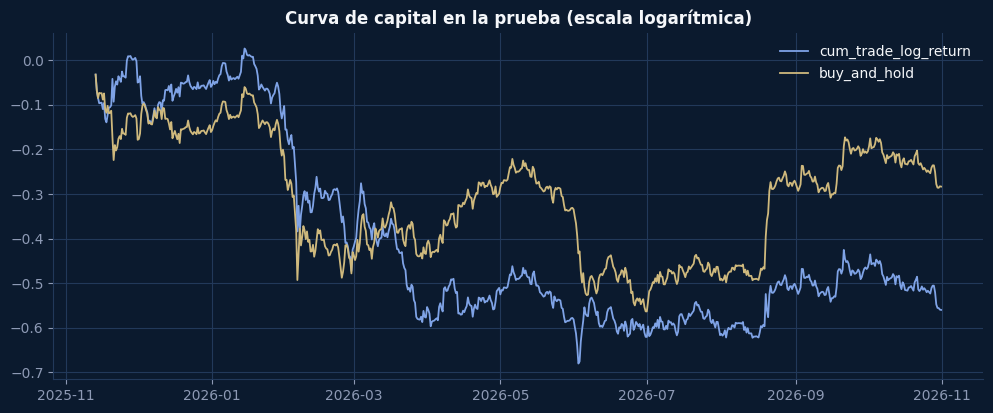

In [32]:
# la estrategia, antes de comisiones, al lado de simplemente comprar y mantener
trades = trades.with_columns(pl.col('close_log_return').cum_sum().alias('buy_and_hold'))
research.plot_multiple_lines(trades, ['cum_trade_log_return', 'buy_and_hold'], 'Curva de capital en la prueba (escala logarítmica)')

### Contar las Operaciones

In [33]:
# 1 operación al abrir, 2 al dar la vuelta (cerrar y abrir la contraria) y 0 si la dirección se mantiene
trades = trades.with_columns((pl.col('dir_signal') - pl.col('dir_signal').shift().fill_null(0)).abs().alias('no_trades'))
trades.select('datetime', 'y_hat', 'dir_signal', 'no_trades')

datetime,y_hat,dir_signal,no_trades
datetime[μs],f64,f64,f64
2025-11-13 12:00:00,0.000478,1.0,1.0
2025-11-14 00:00:00,0.000004,1.0,0.0
2025-11-14 12:00:00,0.000722,1.0,0.0
2025-11-15 00:00:00,-0.000094,-1.0,2.0
2025-11-15 12:00:00,-0.000352,-1.0,0.0
…,…,…,…
2026-10-29 12:00:00,0.00046,1.0,0.0
2026-10-30 00:00:00,0.000472,1.0,0.0
2026-10-30 12:00:00,0.000111,1.0,0.0


In [34]:
# velas en largo, velas en corto y número total de operaciones
(trades['dir_signal'] == 1).sum(), (trades['dir_signal'] == -1).sum(), trades['no_trades'].sum()

(625, 80, 273.0)

---
# T · Tamaño
## Decisión Clave de Estrategia #2: Tamaño de la Operación

In [35]:
# 1. Tamaño constante
# 2. Tamaño compuesto

In [36]:
capital = 100
ratio = 1.0 # se puede experimentar con otras proporciones, como el criterio de Kelly (más abajo)
trade_value = ratio * capital

# valor de entrada y valor de salida de la operación
trades = trades.with_columns(
    pl.lit(trade_value).alias('entry_trade_value'),
    (trade_value * pl.col('trade_log_return').exp()).alias('exit_trade_value'),
    (trade_value / pl.col('open')).alias('trade_qty'),
).with_columns(
    (pl.col('trade_qty') * pl.col('dir_signal')).alias('signed_trade_qty'),
)

trades.select('datetime','open','close', 'trade_log_return','y_hat','entry_trade_value','exit_trade_value', 'signed_trade_qty')

datetime,open,close,trade_log_return,y_hat,entry_trade_value,exit_trade_value,signed_trade_qty
datetime[μs],f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,99654.3,-0.03205,0.000478,100.0,96.845773,0.000972
2025-11-14 00:00:00,99654.3,96134.6,-0.035958,0.000004,100.0,96.46809,0.001003
2025-11-14 12:00:00,96134.5,94544.9,-0.016674,0.000722,100.0,98.346381,0.00104
2025-11-15 00:00:00,94544.9,95657.3,-0.011697,-0.000094,100.0,98.837099,-0.001058
2025-11-15 12:00:00,95657.3,95560.3,0.001015,-0.000352,100.0,100.101507,-0.001045
…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,77962.6,-0.027432,0.00046,100.0,97.294053,0.001248
2026-10-30 00:00:00,77962.6,77345.9,-0.007942,0.000472,100.0,99.20898,0.001283
2026-10-30 12:00:00,77345.8,77312.6,-0.000431,0.000111,100.0,99.956947,0.001293


### Agregar la Ganancia Bruta de la Operación (Gross PnL)

In [37]:
trades = trades.with_columns((pl.col('exit_trade_value') - pl.col('entry_trade_value')).alias('trade_gross_pnl'))
trades.select('datetime','open','close', 'trade_log_return','entry_trade_value','exit_trade_value', 'trade_gross_pnl')

datetime,open,close,trade_log_return,entry_trade_value,exit_trade_value,trade_gross_pnl
datetime[μs],f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,99654.3,-0.03205,100.0,96.845773,-3.154227
2025-11-14 00:00:00,99654.3,96134.6,-0.035958,100.0,96.46809,-3.53191
2025-11-14 12:00:00,96134.5,94544.9,-0.016674,100.0,98.346381,-1.653619
2025-11-15 00:00:00,94544.9,95657.3,-0.011697,100.0,98.837099,-1.162901
2025-11-15 12:00:00,95657.3,95560.3,0.001015,100.0,100.101507,0.101507
…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,77962.6,-0.027432,100.0,97.294053,-2.705947
2026-10-30 00:00:00,77962.6,77345.9,-0.007942,100.0,99.20898,-0.79102
2026-10-30 12:00:00,77345.8,77312.6,-0.000431,100.0,99.956947,-0.043053


### Agregar las Comisiones de Transacción

In [38]:
taker_fee = binance.TAKER_FEE
maker_fee = binance.MAKER_FEE

# la comisión se paga sobre el valor operado, y solo en las velas donde hay operaciones
trades = trades.with_columns(
    (pl.col('no_trades') * pl.col('entry_trade_value') * taker_fee).alias('taker_fee'),
    (pl.col('no_trades') * pl.col('entry_trade_value') * maker_fee).alias('maker_fee')
)

trades.select('datetime','dir_signal','no_trades','entry_trade_value','trade_gross_pnl','maker_fee','taker_fee')

datetime,dir_signal,no_trades,entry_trade_value,trade_gross_pnl,maker_fee,taker_fee
datetime[μs],f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,1.0,1.0,100.0,-3.154227,0.02,0.05
2025-11-14 00:00:00,1.0,0.0,100.0,-3.53191,0.0,0.0
2025-11-14 12:00:00,1.0,0.0,100.0,-1.653619,0.0,0.0
2025-11-15 00:00:00,-1.0,2.0,100.0,-1.162901,0.04,0.1
2025-11-15 12:00:00,-1.0,0.0,100.0,0.101507,0.0,0.0
…,…,…,…,…,…,…
2026-10-29 12:00:00,1.0,0.0,100.0,-2.705947,0.0,0.0
2026-10-30 00:00:00,1.0,0.0,100.0,-0.79102,0.0,0.0
2026-10-30 12:00:00,1.0,0.0,100.0,-0.043053,0.0,0.0


### Calcular la Ganancia Neta de la Operación (Net PnL)

In [39]:
trades = trades.with_columns(
    (pl.col('trade_gross_pnl')-pl.col('taker_fee')).alias('trade_net_taker_pnl'),
    (pl.col('trade_gross_pnl')-pl.col('maker_fee')).alias('trade_net_maker_pnl'),
)

trades.select('datetime','open','close', 'trade_log_return','signed_trade_qty', 'trade_gross_pnl','trade_net_taker_pnl','trade_net_maker_pnl')

datetime,open,close,trade_log_return,signed_trade_qty,trade_gross_pnl,trade_net_taker_pnl,trade_net_maker_pnl
datetime[μs],f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,99654.3,-0.03205,0.000972,-3.154227,-3.204227,-3.174227
2025-11-14 00:00:00,99654.3,96134.6,-0.035958,0.001003,-3.53191,-3.53191,-3.53191
2025-11-14 12:00:00,96134.5,94544.9,-0.016674,0.00104,-1.653619,-1.653619,-1.653619
2025-11-15 00:00:00,94544.9,95657.3,-0.011697,-0.001058,-1.162901,-1.262901,-1.202901
2025-11-15 12:00:00,95657.3,95560.3,0.001015,-0.001045,0.101507,0.101507,0.101507
…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,77962.6,-0.027432,0.001248,-2.705947,-2.705947,-2.705947
2026-10-30 00:00:00,77962.6,77345.9,-0.007942,0.001283,-0.79102,-0.79102,-0.79102
2026-10-30 12:00:00,77345.8,77312.6,-0.000431,0.001293,-0.043053,-0.043053,-0.043053


### Mostrar las Curvas de Capital con Tamaño Constante

In [40]:
def equity_curve(capital, col_name, suffix):
    return (capital + (pl.col(col_name).cum_sum())).alias(f'equity_curve_{suffix}')

trades = trades.with_columns(
    equity_curve(capital, 'trade_net_taker_pnl', 'taker'),
    equity_curve(capital, 'trade_net_maker_pnl', 'maker'),
    equity_curve(capital, 'trade_gross_pnl', 'gross'),
)
trades.select('datetime','equity_curve_gross','equity_curve_taker','equity_curve_maker')

datetime,equity_curve_gross,equity_curve_taker,equity_curve_maker
datetime[μs],f64,f64,f64
2025-11-13 12:00:00,96.845773,96.795773,96.825773
2025-11-14 00:00:00,93.313863,93.263863,93.293863
2025-11-14 12:00:00,91.660244,91.610244,91.640244
2025-11-15 00:00:00,90.497342,90.347342,90.437342
2025-11-15 12:00:00,90.598849,90.448849,90.538849
…,…,…,…
2026-10-29 12:00:00,53.637101,40.187101,48.257101
2026-10-30 00:00:00,52.84608,39.39608,47.46608
2026-10-30 12:00:00,52.803027,39.353027,47.423027


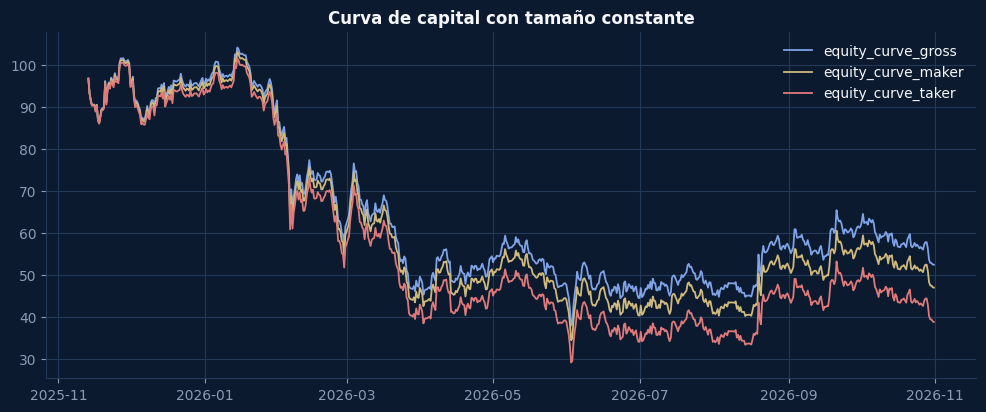

In [41]:
research.plot_multiple_lines(trades, ['equity_curve_gross', 'equity_curve_maker', 'equity_curve_taker'], 'Curva de capital con tamaño constante')

### Calcular el Retorno Neto Total con Tamaño Constante

In [42]:
constant_sizing_net_return = trades['equity_curve_taker'][-1] / capital - 1
constant_sizing_net_return

-0.6125586126116386

In [43]:
# cuánto del resultado se fue en comisiones (como fracción del capital)
trades['taker_fee'].sum() / capital

0.1365

## Experimento con Tamaño Compuesto

In [44]:
# 2 => 102 (100 + 2)
# 1 => 103 (100 + 2 + 1)
# -1 => 102 (100 + 2 + 1 - 1)

In [45]:
log_return_1 = 0.005439
pnl1 = capital * np.exp(log_return_1)
pnl1

np.float64(100.54538182137402)

In [46]:
log_return_2 = 0.008597
pnl2 = pnl1 * np.exp(log_return_2)
pnl2

np.float64(101.41349671401576)

In [47]:
log_return_3 = 0.001385
pnl3 = pnl2 * np.exp(log_return_3)
pnl3

np.float64(101.55405171883751)

### Aditividad Temporal

In [48]:
capital * np.exp(log_return_1 + log_return_2 + log_return_3)

np.float64(101.55405171883751)

### Agregar el Tamaño Compuesto

In [49]:
# cada vela opera todo el capital que dejó la anterior, ya descontada la comisión
growth = pl.col('trade_log_return').exp() - pl.col('no_trades') * taker_fee      # factor por el que se multiplica el capital en la vela

trades = trades.with_columns(
    (capital * growth.cum_prod()).alias('equity_curve_taker'),
).with_columns(
    pl.col('equity_curve_taker').shift().fill_null(capital).alias('entry_trade_value'),
).with_columns(
    (pl.col('entry_trade_value') * pl.col('trade_log_return').exp()).alias('exit_trade_value'),
    (pl.col('entry_trade_value') / pl.col('open') * pl.col('dir_signal')).alias('signed_trade_qty'),
).with_columns(
    (pl.col('exit_trade_value')-pl.col('entry_trade_value')).alias('trade_gross_pnl'),
)
trades.select('datetime','open','close','trade_log_return','entry_trade_value','exit_trade_value','signed_trade_qty','trade_gross_pnl')

datetime,open,close,trade_log_return,entry_trade_value,exit_trade_value,signed_trade_qty,trade_gross_pnl
datetime[μs],f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,99654.3,-0.03205,100.0,96.845773,0.000972,-3.154227
2025-11-14 00:00:00,99654.3,96134.6,-0.035958,96.795773,93.377033,0.000971,-3.418739
2025-11-14 12:00:00,96134.5,94544.9,-0.016674,93.377033,91.832933,0.000971,-1.5441
2025-11-15 00:00:00,94544.9,95657.3,-0.011697,91.832933,90.765006,-0.000971,-1.067926
2025-11-15 12:00:00,95657.3,95560.3,0.001015,90.673174,90.765213,-0.000948,0.092039
…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,77962.6,-0.027432,51.967157,50.560953,0.000649,-1.406204
2026-10-30 00:00:00,77962.6,77345.9,-0.007942,50.560953,50.161006,0.000649,-0.399947
2026-10-30 12:00:00,77345.8,77312.6,-0.000431,50.161006,50.13941,0.000649,-0.021596


### Agregar las Comisiones de Transacción

In [50]:
trades = research.add_tx_fees(trades, binance.MAKER_FEE, binance.TAKER_FEE)
trades.select('datetime','no_trades','entry_trade_value','exit_trade_value','tx_fee_maker','tx_fee_taker')

datetime,no_trades,entry_trade_value,exit_trade_value,tx_fee_maker,tx_fee_taker
datetime[μs],f64,f64,f64,f64,f64
2025-11-13 12:00:00,1.0,100.0,96.845773,0.02,0.05
2025-11-14 00:00:00,0.0,96.795773,93.377033,0.0,0.0
2025-11-14 12:00:00,0.0,93.377033,91.832933,0.0,0.0
2025-11-15 00:00:00,2.0,91.832933,90.765006,0.036733,0.091833
2025-11-15 12:00:00,0.0,90.673174,90.765213,0.0,0.0
…,…,…,…,…,…
2026-10-29 12:00:00,0.0,51.967157,50.560953,0.0,0.0
2026-10-30 00:00:00,0.0,50.560953,50.161006,0.0,0.0
2026-10-30 12:00:00,0.0,50.161006,50.13941,0.0,0.0


### Agregar la Ganancia Neta de la Operación

In [51]:
trades = trades.with_columns(
    (pl.col('trade_gross_pnl') - pl.col('tx_fee_taker')).alias('trade_net_taker_pnl')
)
trades.select('datetime','open','close','close_log_return','y_hat','entry_trade_value','exit_trade_value','trade_gross_pnl','trade_net_taker_pnl')

datetime,open,close,close_log_return,y_hat,entry_trade_value,exit_trade_value,trade_gross_pnl,trade_net_taker_pnl
datetime[μs],f64,f64,f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,102900.1,99654.3,-0.03205,0.000478,100.0,96.845773,-3.154227,-3.204227
2025-11-14 00:00:00,99654.3,96134.6,-0.035958,0.000004,96.795773,93.377033,-3.418739,-3.418739
2025-11-14 12:00:00,96134.5,94544.9,-0.016674,0.000722,93.377033,91.832933,-1.5441,-1.5441
2025-11-15 00:00:00,94544.9,95657.3,0.011697,-0.000094,91.832933,90.765006,-1.067926,-1.159759
2025-11-15 12:00:00,95657.3,95560.3,-0.001015,-0.000352,90.673174,90.765213,0.092039,0.092039
…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,77962.6,-0.027432,0.00046,51.967157,50.560953,-1.406204,-1.406204
2026-10-30 00:00:00,77962.6,77345.9,-0.007942,0.000472,50.560953,50.161006,-0.399947,-0.399947
2026-10-30 12:00:00,77345.8,77312.6,-0.000431,0.000111,50.161006,50.13941,-0.021596,-0.021596


### Mostrar la Curva de Capital (Compuesta)

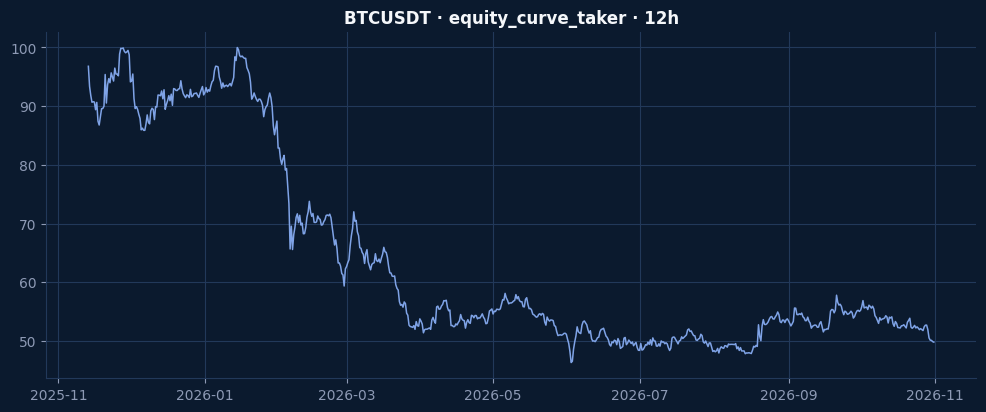

In [52]:
research.plot_static_timeseries(trades, sym, 'equity_curve_taker', time_interval)

### Calcular el Retorno Neto Total con Tamaño Compuesto

In [53]:
compound_total_net_return = trades['equity_curve_taker'][-1] / capital - 1
compound_total_net_return

-0.5016551005297087

In [54]:
constant_sizing_net_return

-0.6125586126116386

In [55]:
# el interés compuesto trabaja en los dos sentidos: al perder, cada operación siguiente es más pequeña y la caída se frena
np.round(compound_total_net_return - constant_sizing_net_return, 2)

np.float64(0.11)

### Criterio de Kelly: ¿qué fracción del capital operar?

In [56]:
# la fracción que maximiza el crecimiento del capital es (retorno medio) / (varianza) de las operaciones
# se estima con la validación, que es lo único que conocíamos antes de abrir la prueba, y ya descontadas las comisiones
val_trades = research.add_trade_log_returns(research.add_model_predictions(val_trades, model, features))
val_net_returns = val_trades['trade_log_return'] - val_trades['no_trades'] * taker_fee

kelly = val_net_returns.mean() / val_net_returns.var()
kelly

3.444017171579802

In [57]:
# Kelly supone que la ventaja estimada es exacta. Como nunca lo es, en la práctica se usa la mitad o menos
kelly / 2

1.722008585789901

## Decisión Clave de Estrategia #3: Apalancamiento

In [58]:
# apalancarse es pedir dinero prestado para aumentar las ganancias

In [59]:
leverage = 4
leverage * capital

400

In [60]:
# en teoría, multiplicamos el tamaño de la operación para aumentar los retornos

In [61]:
# no estamos multiplicando el retorno de cada operación

In [62]:
# recuerda: amplifica TANTO las ganancias como las pérdidas, por eso es importante tener un valor esperado positivo

In [63]:
# el apalancamiento solo funciona con un modelo de Sharpe alto. Cuanto más se reduce el riesgo, menores son los drawdowns y más apalancamiento se puede usar

In [64]:
# decisión clave 3: ¿usamos apalancamiento? si es así, ¿cuánto? ¿cuál es el punto óptimo?

In [65]:
# no es una fórmula mágica para multiplicar ganancias: puede arruinarte con facilidad

In [66]:
trades = research.add_compounding_trades(trades, capital, leverage, maker_fee, taker_fee)
trades.select('datetime','dir_signal','entry_trade_value','exit_trade_value','trade_net_taker_pnl','equity_curve_gross','equity_curve_taker')

datetime,dir_signal,entry_trade_value,exit_trade_value,trade_net_taker_pnl,equity_curve_gross,equity_curve_taker
datetime[μs],f64,f64,f64,f64,f64,f64
2025-11-13 12:00:00,1.0,400.0,387.38309,-12.81691,87.38309,87.18309
2025-11-14 00:00:00,1.0,348.732362,336.415449,-12.316912,75.037923,74.866178
2025-11-14 12:00:00,1.0,299.464712,294.512706,-4.952005,70.074557,69.914173
2025-11-15 00:00:00,-1.0,279.65669,276.404559,-3.531788,66.814965,66.382385
2025-11-15 12:00:00,-1.0,265.529538,265.799068,0.26953,67.086252,66.651915
…,…,…,…,…,…,…
2026-10-29 12:00:00,1.0,10.339318,10.059542,-0.279777,3.970346,2.305053
2026-10-30 00:00:00,1.0,9.220212,9.147279,-0.072934,3.844721,2.232119
2026-10-30 12:00:00,1.0,8.928477,8.924633,-0.003844,3.8381,2.228275


In [67]:
trades['equity_curve_taker'][-1] / capital - 1

-0.9782573035464116

## ¿Y si subimos a 8x de apalancamiento?

In [68]:
trades_8x = research.add_compounding_trades(trades, capital, 8, maker_fee, taker_fee)

In [69]:
trades_8x['equity_curve_taker'][-1] / capital - 1

-0.9999840013317727

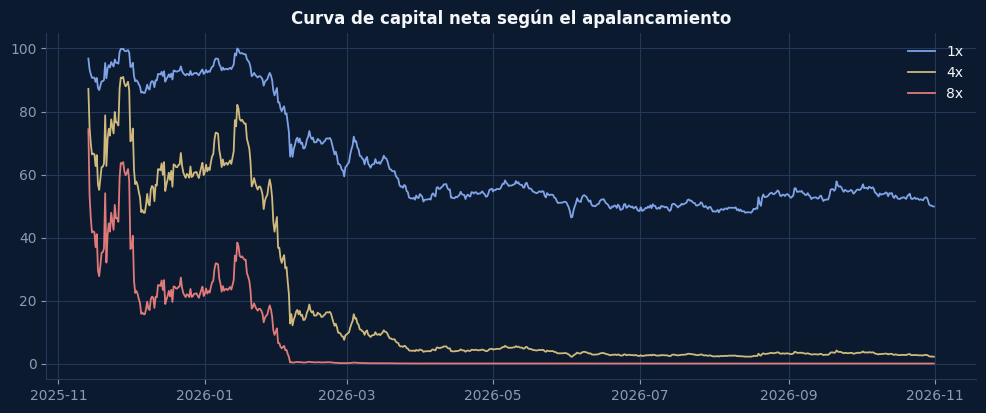

In [70]:
# el mismo modelo y las mismas señales con 1x, 4x y 8x
leverage_curves = trades.select('datetime').with_columns(
    research.add_compounding_trades(trades, capital, 1, maker_fee, taker_fee)['equity_curve_taker'].alias('1x'),
    trades['equity_curve_taker'].alias('4x'),
    trades_8x['equity_curve_taker'].alias('8x'),
)
research.plot_multiple_lines(leverage_curves, ['1x', '4x', '8x'], 'Curva de capital neta según el apalancamiento')

In [71]:
# el apalancamiento no cambia la ventaja del modelo: solo cambia el tamaño de lo que se gana o se pierde

### La Tasa de Acierto no Cambió

In [72]:
trades.select((pl.col("trade_log_return") > 0).mean())

trade_log_return
f64
0.479433


### Considerar la Liquidación (el precio se mueve demasiado en contra)

In [73]:
# La liquidación es cuando lo perdemos todo. Con demasiado apalancamiento, un cambio pequeño de precio puede dejarnos en cero.

In [74]:
# el apalancamiento es un arma de doble filo: amplifica las ganancias, pero en exceso puede hacerte perder todo el dinero

In [75]:
# Capital = Margen de Mantenimiento
# el cálculo varía según el exchange

In [76]:
maintenance_margin = 0.005

def long_liquidation_price(p, l, mmr):
    return (p * l) / (l + 1 - mmr * l)

def short_liquidation_price(p, l, mmr):
    return (p * l) / (l - 1 + mmr * l)

### Cómo Afecta el Apalancamiento a las Posiciones Largas

In [77]:
long_liquidation_price(200, 2, maintenance_margin)

133.7792642140468

In [78]:
long_liquidation_price(200, 4, maintenance_margin)

160.64257028112448

In [79]:
long_liquidation_price(200, 10, maintenance_margin)

182.64840182648402

In [80]:
long_liquidation_price(200, 50, maintenance_margin)

197.04433497536945

### Cómo Afecta el Apalancamiento a las Posiciones Cortas

In [81]:
short_liquidation_price(200, 2, maintenance_margin)

396.03960396039605

In [82]:
short_liquidation_price(200, 4, maintenance_margin)

264.9006622516556

In [83]:
short_liquidation_price(200, 10, maintenance_margin)

220.99447513812152

In [84]:
short_liquidation_price(200, 60, maintenance_margin)

202.36087689713324

### Agregar los Precios de Liquidación

In [85]:
leverage

4

In [86]:
def add_liquidations(trades, leverage):
    return trades.with_columns(
        pl.when(pl.col("dir_signal") == 1)  # posición larga
          .then(long_liquidation_price(pl.col("open"), leverage, maintenance_margin))
          .otherwise(short_liquidation_price(pl.col("open"), leverage, maintenance_margin))  # posición corta
          .alias("liquidation_price"),
        # Peor precio de la vela según la dirección
        pl.when(pl.col("dir_signal") == 1).then(pl.col("low")).otherwise(pl.col("high")).alias("worst_price"),
    ).with_columns(
        # Indicador de liquidación: el peor precio de la vela alcanzó el precio de liquidación
        pl.when(pl.col("dir_signal") == 1)
          .then(pl.col("low") <= pl.col("liquidation_price"))
          .otherwise(pl.col("high") >= pl.col("liquidation_price"))
          .alias("liquidated")
    )

trades = add_liquidations(trades, leverage)
trades.select('datetime','open','low','high','close','dir_signal','worst_price','liquidation_price','liquidated')

datetime,open,low,high,close,dir_signal,worst_price,liquidation_price,liquidated
datetime[μs],f64,f64,f64,f64,f64,f64,f64,bool
2025-11-13 12:00:00,102900.1,97959.0,103456.0,99654.3,1.0,97959.0,82650.682731,false
2025-11-14 00:00:00,99654.3,95597.9,99862.8,96134.6,1.0,95597.9,80043.614458,false
2025-11-14 12:00:00,96134.5,93955.0,97377.6,94544.9,1.0,93955.0,77216.465863,false
2025-11-15 00:00:00,94544.9,94523.9,96800.0,95657.3,-1.0,96800.0,125225.033113,false
2025-11-15 12:00:00,95657.3,95072.1,96439.6,95560.3,-1.0,96439.6,126698.410596,false
…,…,…,…,…,…,…,…,…
2026-10-29 12:00:00,80130.9,77868.4,81953.7,77962.6,1.0,77868.4,64362.168675,false
2026-10-30 00:00:00,77962.6,76444.0,78776.5,77345.9,1.0,76444.0,62620.562249,false
2026-10-30 12:00:00,77345.8,76270.0,78081.3,77312.6,1.0,76270.0,62125.140562,false


### Buscar Operaciones Liquidadas

In [87]:
trades.filter(pl.col("liquidated") == True).select('datetime','open','low','high','dir_signal','liquidation_price')

datetime,open,low,high,dir_signal,liquidation_price
datetime[μs],f64,f64,f64,f64,f64


In [88]:
# con 8x basta un movimiento de ~11% en contra dentro de una vela de 12 horas
add_liquidations(trades, 8).filter(pl.col("liquidated") == True).select('datetime','open','low','high','dir_signal','liquidation_price')

datetime,open,low,high,dir_signal,liquidation_price
datetime[μs],f64,f64,f64,f64,f64
2026-02-05 12:00:00,70279.1,62233.3,70848.6,1.0,62749.196429


---
# L · Libre de sesgos
Un backtest puede mentir de tres formas. Antes de creerle a una curva de capital, hay que descartarlas.

### Sesgo de Anticipación (*look-ahead bias*)

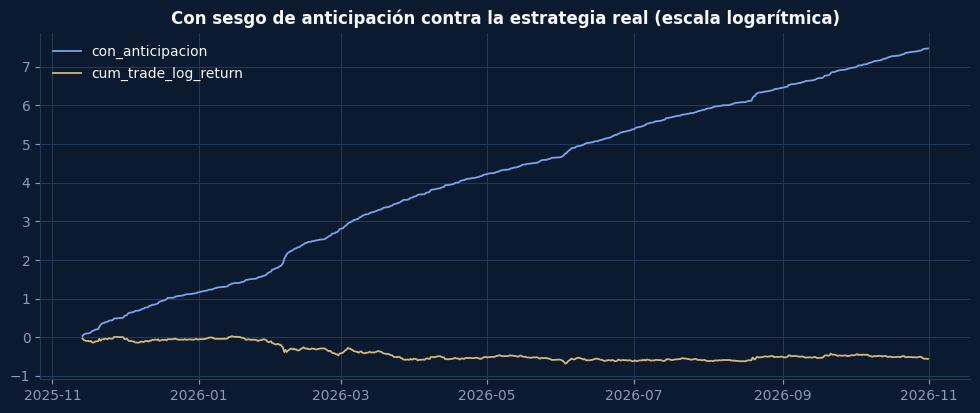

In [89]:
# si la señal usa el cierre de la misma vela que opera (un .shift() olvidado), el backtest ve el futuro y la curva es un milagro
leak = trades.with_columns(
    (pl.col('close_log_return').sign() * pl.col('close_log_return')).cum_sum().alias('con_anticipacion')
)
research.plot_multiple_lines(leak, ['con_anticipacion', 'cum_trade_log_return'], 'Con sesgo de anticipación contra la estrategia real (escala logarítmica)')

In [90]:
# multiplicar el capital por esto en un año no es una estrategia: es un error de programación
np.exp(leak['con_anticipacion'][-1])

np.float64(1756.1444122925438)

### Sesgo de Selección (*overfitting*)

In [91]:
# el modelo se eligió por ser el mejor de 14 en la validación. ¿Rinde igual en la prueba, que no participó en la elección?
annualized_rate = research.sharpe_annualization_factor(time_interval)
pl.DataFrame([
    {'tramo': 'validación', **research.eval_model_performance(val_trades['close_log_return'], val_trades['y_hat'], features, target, annualized_rate)},
    {'tramo': 'prueba', **research.eval_model_performance(trades['close_log_return'], trades['y_hat'], features, target, annualized_rate)},
]).select('tramo', 'no_trades', 'win_rate', 'ev', 'total_log_return', 'max_drawdown', 'sharpe')

tramo,no_trades,win_rate,ev,total_log_return,max_drawdown,sharpe
str,i64,f64,f64,f64,f64,f64
"""validación""",705,0.524823,0.001152,0.812152,-0.270243,1.864097
"""prueba""",705,0.479433,-0.000794,-0.559736,-0.706332,-1.391664


In [92]:
# comprar y mantener en cada tramo: la validación fue alcista y la prueba, bajista
val_trades['close_log_return'].sum(), trades['close_log_return'].sum()

(0.10047021432553938, -0.2831881360882536)

### Prueba de Permutaciones: ¿la estrategia le gana al azar?

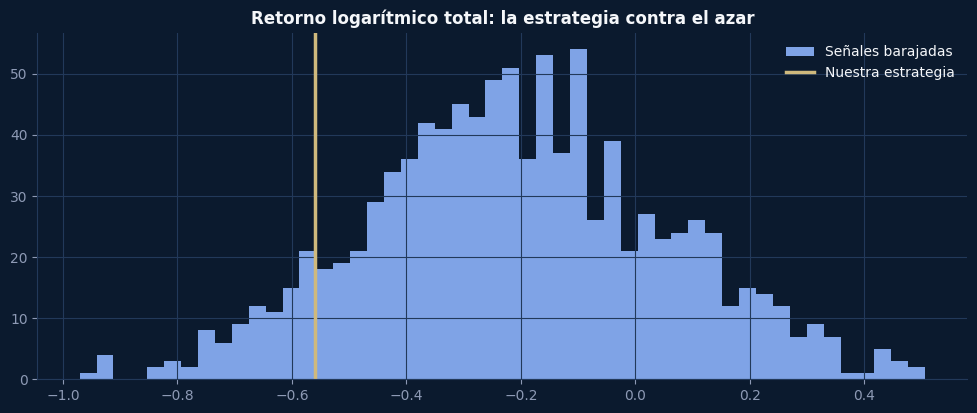

In [93]:
# barajamos las señales 1.000 veces: mismas velas, misma cantidad de largos y cortos, pero en momentos al azar
random_returns = research.permutation_test(trades, no_permutations=1000)
strategy_return = trades['trade_log_return'].sum()
research.plot_permutation_test(random_returns, strategy_return)

In [94]:
# valor p: fracción de las estrategias al azar que rinden igual o mejor que la nuestra (se busca menos de 0.05)
(random_returns >= strategy_return).mean()

np.float64(0.907)

### Veredicto

In [95]:
# 1. Simulación: en la prueba la estrategia pierde antes de comisiones, y las comisiones agrandan la pérdida
# 2. Tamaño: Kelly, estimado con la validación, recomendaba apalancarse; en la prueba eso habría destruido la cuenta
# 3. Libre de sesgos: el Sharpe de la validación no se repite en la prueba y la estrategia no le gana al azar

# el modelo no tiene una ventaja demostrada: aprendió el régimen alcista del entrenamiento (su sesgo lo mantiene casi siempre en largo)
# esto es lo que el método está diseñado para descubrir ANTES de arriesgar capital

In [96]:
# fin del notebook 2
# en el notebook 3 (E · Ejecución) programamos el sistema completo y lo conectamos a una cuenta demo de Binance:
# un bot funcional. Funcional no es lo mismo que rentable: el alfa es la pieza que se cambia

# temas que no cubrimos - esto es solo una base sobre la cual construir
# alpha decay (también llamado deriva del modelo) => el desempeño de la predicción se deteriora con el tiempo
# impacto de mercado => no operamos tamaños grandes => si lo hiciéramos, podríamos mover el mercado en nuestra contra
# comisiones de fondeo (funding) y reembolsos
# slippage => no siempre obtenemos el mejor precio; podemos ejecutar a precios peores que la punta del libro (mejor bid/ask)